In [1]:
%reset -f
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from datetime import datetime
from scipy.stats import gaussian_kde

import sys
sys.path.append("../../tools")
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(acht)


In [3]:
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
MaxNum = emodel["NumSpecies"]


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [4]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

cmap = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#f3f3f3", "#858585"]
)

df = pd.read_csv("gamma5.csv")
#df = pd.read_csv("random2.csv")
df = df.dropna()


In [5]:
def fig_pdf_name(property, emer_pro):

    if property == "density":
        plt.xlim(0, 1)
        plt.xlabel("Density",fontsize=7)
    elif property == "pos_inall":
        plt.xlim(0, 1)
        plt.xlabel("Positive interaction proportion",fontsize=7)
    elif property == "gamma_neg_mean":
        plt.xlim(0.1, 7)
        plt.xlabel(r"Mean interaction strength $\gamma$",fontsize=7)
    else:
        raise ValueError("Invalid property value**")

    if emer_pro == "relative_H":
        plt.ylim(0, 1)
        #plt.ylabel(r"Relative stable state entropy $\bar{\mathcal{H}}$",fontsize=7)
        plt.ylabel(r"Effective diversification $\mathcal{H}$",fontsize=7)
    elif emer_pro == "H":
        plt.ylim(1, 5)
        plt.ylabel(r"Stable state entropy $\mathcal{H}$",fontsize=7)
    elif emer_pro == "relative_D":
        plt.ylim(0, 1)
        #plt.ylabel(r"Relative diversity $\bar{\mathcal{D}}$",fontsize=7)
        plt.ylabel(r"Diversity realization $\mathcal{D}$",fontsize=7)
    elif emer_pro == "D":
        plt.ylim(1, 20)
        plt.ylabel(r"Diversity $\mathcal{D}$",fontsize=7)
    else:
        raise ValueError("Invalid property value**")   

    plt.tick_params(direction='in')
    plt.savefig(f"A_{property}_{emer_pro}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight', transparent=True)
    plt.show()

def density_pos_gamma(df_sub, cmap, device, property="density", emer_pro="D"):

    '''
    property: "density", "pos_inall", "gamma_neg_mean"
    emer_pro: "D", "relative_D", "H", "relative_H"
    '''

    x = df_sub[property].values
    Xnum_pad = df_sub.iloc[:, :(MaxNum**2+MaxNum)].values
    if emer_pro == "H" or emer_pro == "relative_H":
        y_pred = epredictor.predict_array_MD(Xnum_pad, device)
    elif emer_pro == "D" or emer_pro == "relative_D":
        y_pred = dpredictor.predict_array_MD(Xnum_pad, device)
    else:
        raise ValueError("Invalid emer_pro value**")
    
    richness = df_sub["richness"].values
    y_pred_real = y_pred * (richness - 1) + 1

    plt.figure(figsize=(1,1), dpi=200)

    mask = (y_pred >= 0) & (y_pred <= 1)

    if emer_pro == "relative_H" or emer_pro == "relative_D":
        xlabel = x[mask]
        ylabel = y_pred[mask]
    elif emer_pro == "H" or emer_pro == "D":
        xlabel = x[mask]
        ylabel = y_pred_real[mask]
    else:
        raise ValueError("Invalid emer_pro value**")
    
    hb = plt.hexbin(
        xlabel, ylabel, 
        gridsize=50, # number of hexagons
        mincnt=1, # minimum number of points in a hexagon to draw it
        cmap=cmap,
        vmin=0,
        vmax=200, # set upper bound for color mapping
        edgecolors='none',
        # alpha=0.8,
        rasterized=True)

    # cbar = plt.colorbar(hb)
    # cbar.set_label("Count")
    fig_pdf_name(property, emer_pro)


**Stable state**

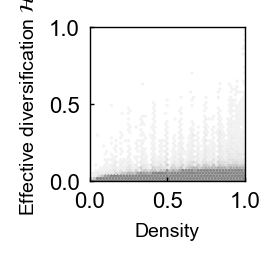

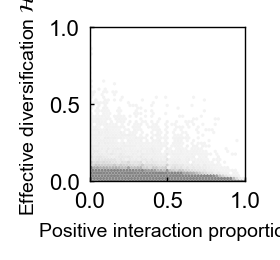

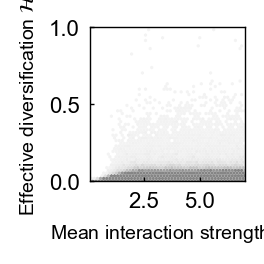

In [ ]:
df_sub = df[df["richness"]>=4]
density_pos_gamma(df_sub, cmap, device, property="density", emer_pro="relative_H")
density_pos_gamma(df_sub, cmap, device, property="pos_inall", emer_pro="relative_H")
density_pos_gamma(df_sub, cmap, device, property="gamma_neg_mean", emer_pro="relative_H")


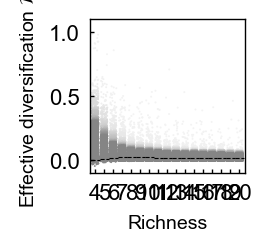

In [11]:
from matplotlib.colors import Normalize

#df_sub = df.sample(n=2000, random_state=42)
# df_sub = df[df["pos_inall"] < 0.2]
# df_sub = df[df["density"] > 0.8]

rng = np.random.default_rng(42)   # fix random seed to ensure reproducibility

classes = sorted(df_sub["richness"].astype(int).unique())
all_entropy = []

for spe, subsub in df_sub.groupby("richness"):

    Xnum_pad = subsub.iloc[:, :(MaxNum**2+MaxNum)].values
    # y_pred = epredictor.predict_array_MD(Xnum_pad, device)
    # entropy = y_pred*(spe-1)+1
    entropy = epredictor.predict_array_MD(Xnum_pad, device)
    all_entropy.append(entropy)

positions = np.arange(1, len(classes)+1)

fig, ax = plt.subplots(figsize=(1.0, 1.0), dpi=200)
ax.set_axisbelow(False)

# First compute point density for all groups
all_density = []
for data in all_entropy:
    d = gaussian_kde(data)(data)
    all_density.append(d)

# # Unified color range
# vmax = np.percentile(np.concatenate(all_density), 5)
# norm = Normalize(vmin=0, vmax=vmax)

for x, data, density in zip(positions, all_entropy, all_density):

    width = 0.36
    xx = x + np.random.uniform(-width, width, len(data))

    idx = density.argsort()

    xx = xx[idx]
    yy = data[idx]
    density = density[idx]

    # Compute color range separately for each richness
    vmax = np.percentile(density, 5)
    norm = Normalize(vmin=0, vmax=vmax)

    ax.scatter(
        xx,
        yy,
        c=density,
        cmap=cmap,
        norm=norm,
        s=0.5,
        edgecolor="none",
        zorder=2,
        rasterized=True,
    )

    median = np.median(data)

    ax.hlines(
        median,
        x-0.5,
        x+0.5,
        color="black",
        linewidth=0.4,
        linestyle="--",
        zorder=3
    )

ax.set_xticks(positions)
ax.set_xticklabels(classes)

ax.set_xlim(0.4, len(classes)+0.6)
ax.set_ylim(-0.1, 1.1)

ax.tick_params(direction="in")

ax.set_xlabel("Richness", fontsize=7)
ax.set_ylabel(r"Effective diversification $\mathcal{H}$", fontsize=7)

plt.savefig(f"A_richness_relative_H_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight', transparent=True)

plt.show()


**Relative diversity**

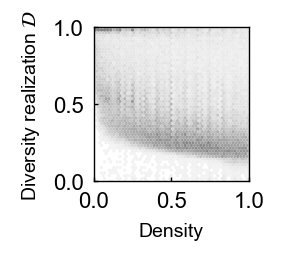

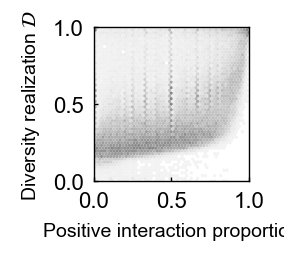

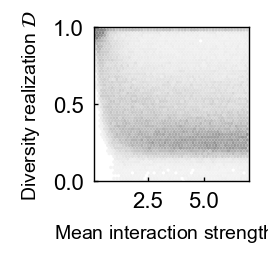

In [8]:
# df_sub = df
density_pos_gamma(df_sub, cmap, device, property="density", emer_pro="relative_D")
density_pos_gamma(df_sub, cmap, device, property="pos_inall", emer_pro="relative_D")
density_pos_gamma(df_sub, cmap, device, property="gamma_neg_mean", emer_pro="relative_D")


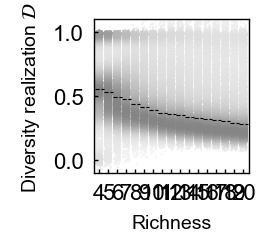

In [ ]:
# df_sub = df
# df_sub = df[df["pos_inall"] < 0.2]
# df_sub = df[df["density"] > 0.8]

rng = np.random.default_rng(42)   # fix random seed to ensure reproducibility

classes = sorted(df_sub["richness"].astype(int).unique())
all_diversity = []
for spe, subsub in df_sub.groupby("richness"):
    Xnum_pad = subsub.iloc[:, :(MaxNum**2+MaxNum)].values
    y_pred = dpredictor.predict_array_MD(Xnum_pad, device)
    all_diversity.append(y_pred)

positions = np.arange(1, len(classes)+1)

fig, ax = plt.subplots(figsize=(1.0, 1.0), dpi=200)
ax.set_axisbelow(False)

for x, data in zip(positions, all_diversity):

    width = 0.36
    xx = x + np.random.uniform(-width, width, len(data))# horizontal jitter
    density = gaussian_kde(data)(data) # point density (along y-direction only)
    idx = density.argsort() # draw high-density points last so they are not covered

    xx = xx[idx]
    yy = data[idx]
    density = density[idx]

    ax.scatter(
        xx, yy,
        c=density,
        cmap=cmap,
        s=0.5,
        edgecolor="none",
        zorder=2,
        rasterized=True
    )

    # median (can also change to mean)
    median = np.median(data)

    ax.hlines(
        median,
        x-0.5,
        x+0.5,
        color="black",
        linewidth=0.4,
        linestyle="--",
        zorder=3
    )

ax.set_xticks(positions)
ax.set_xticklabels(classes)

ax.set_xlim(0.4, len(classes)+0.6)
ax.set_ylim(-0.1,1.1)

ax.tick_params(direction="in")

ax.set_xlabel("Richness", fontsize=7)
#ax.set_ylabel(r"Relative diversity $\bar{\mathcal{D}}$", fontsize=7)
ax.set_ylabel(r"Diversity realization $\mathcal{D}$", fontsize=7)

plt.savefig(f"A_richness_relative_D_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight', transparent=True)

plt.show()
